<a href="https://colab.research.google.com/github/chantika-maharani/Project-UAS-Dataset8/blob/main/01_eksplorasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Tahap 1: Eksplorasi Data (EDA) — Paket 8: Estimation of Obesity Levels**




**Mata Kuliah:** Pembelajaran Mesin (INF62325) — Kelas 5C

**Program Studi:** S1 Informatika, UIN Siber Syekh Nurjati Cirebon

**Paket Dataset:** Paket 8 — Estimation of Obesity Levels Based on Eating Habits and Physical Condition (UCI Machine Learning Repository ID: 544)

**Metode Kelompok:** Klastering (Unsupervised Learning dengan K-Means)


**Anggota Kelompok:**
1. Chantika Maharani (2488010080)
2. Intan Fairuz Nur Asiyah (2488010005)
3. Tiara Salsabila (2488010045)

---
### Pernyataan Unit Analisis & Tujuan Pemodelan
* **Unit Analisis:** Satu baris data dalam dataset ini mewakili satu individu responden (dari Meksiko, Peru, dan Kolombia) yang mencatat informasi kebiasaan makan, kondisi fisik, dan tingkat obesitasnya.
* **Tujuan Pemodelan:** Menerapkan algoritma klastering *unsupervised* (**K-Means**) untuk mengelompokkan responden ke dalam beberapa klaster alami berdasarkan pola makan dan aktivitas fisik, tanpa melibatkan variabel target kelas (`NObeyesdad`) selama pembentukan klaster untuk menghindari kebocoran data (*data leakage*).

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur gaya visualisasi
sns.set_theme(style="whitegrid")

# Langkah 1: Memuat berkas dataset
df = pd.read_csv('ObesityDataSet_raw_and_data_sinthetic.csv')

# Membersihkan karakter tersembunyi pada nama kolom jika ada
df.columns = df.columns.str.strip()

print("Ukuran dataset (baris, kolom):", df.shape)
display(df.head(5))

Ukuran dataset (baris, kolom): (2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [6]:
# Memeriksa tipe data setiap kolom dan jumlah non-null
df.info()

# Ringkasan statistik kolom numerik dan target kategori
display(df.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])
display(df.describe(include='object'))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF                             21

,count,mean,std,min,50%,max
Age,2111.0,24.312600,6.345968,14.00,22.777890,61.00
Height,2111.0,1.701677,0.093305,1.45,1.700499,1.98
Weight,2111.0,86.586058,26.191172,39.00,83.000000,173.00
FCVC,2111.0,2.419043,0.533927,1.00,2.385502,3.00
NCP,2111.0,2.685628,0.778039,1.00,3.000000,4.00
CH2O,2111.0,2.008011,0.612953,1.00,2.000000,3.00
FAF,2111.0,1.010298,0.850592,0.00,1.000000,3.00
TUE,2111.0,0.657866,0.608927,0.00,0.625350,2.00


,Gender,family_history_with_overweight,FAVC,CAEC,SMOKE,SCC,CALC,MTRANS,NObeyesdad
count,2111,2111,2111,2111,2111,2111,2111,2111,2111
unique,2,2,2,4,2,2,4,5,7
top,Male,yes,yes,Sometimes,no,no,Sometimes,Public_Transportation,Obesity_Type_I
freq,1068,1726,1866,1765,2067,2015,1401,1580,351


### Temuan Langkah 1 & 2 (Struktur, Ukuran & Tipe Data)
1. **Ukuran Data:** Berkas dataset terbaca utuh sebesar **2.111 baris × 17 kolom** (16 fitur dan 1 variabel target kelas `NObeyesdad`), sesuai dengan spesifikasi Paket 8 (Estimation of Obesity Levels).
2. **Struktur Kolom:** Terdiri dari 8 kolom numerik (tipe *float64*) dan 9 kolom kategorik/objek (*object*).
3. **Karakteristik Fitur:** Mencakup data fisik responden (seperti usia, tinggi, berat badan) serta informasi gaya hidup dan kebiasaan makan.



In [7]:
# 1. Memeriksa nilai hilang (NaN)
hilang = df.isna().sum()
print("1. Jumlah nilai hilang (NaN):")
print(hilang[hilang > 0] if hilang.sum() > 0 else "Tidak ada nilai hilang (0).")

# 2. Memeriksa baris duplikat identik
total_duplikat = df.duplicated().sum()
print(f"\n2. Jumlah baris duplikat identik: {total_duplikat}")

# 3. Memeriksa kolom konstan
n_unique = df.nunique()
kolom_konstan = list(n_unique[n_unique <= 1].index)
print(f"\n3. Kolom konstan (nilai sama semua): {kolom_konstan if kolom_konstan else 'Tidak ada'}")

# 4. Memeriksa keunikan target kelas
print(f"\n4. Nilai unik kolom target (NObeyesdad): {df['NObeyesdad'].unique().tolist()}")

1. Jumlah nilai hilang (NaN):
Tidak ada nilai hilang (0).

2. Jumlah baris duplikat identik: 24

3. Kolom konstan (nilai sama semua): Tidak ada

4. Nilai unik kolom target (NObeyesdad): ['Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II', 'Obesity_Type_I', 'Insufficient_Weight', 'Obesity_Type_II', 'Obesity_Type_III']


### Temuan Langkah 3 (Pemeriksaan Mutu Data)
* **Nilai Hilang & Kolom Konstan:** Tidak ditemukan nilai kosong (`NaN` / 0) di seluruh kolom dataset, serta tidak ada kolom konstan (seluruh baris bernilai sama).
* **Baris Duplikat:** Ditemukan **24 baris duplikat identik** yang nantinya akan dibersihkan (*drop*) pada tahap praproses (`02_praproses.ipynb`) agar tidak memberikan bobot frekuensi ganda yang bias pada pembentukan klaster K-Means.
* **Penanganan Variabel Target:** Kolom `NObeyesdad` memiliki 7 kategori tingkat obesitas, yang **wajib dikeluarkan dari fitur masukan K-Means** karena metode ini bersifat *unsupervised* (tanpa melibatkan label target agar terhindar dari kebocoran data/*data leakage*).

In [10]:
# 4. Sebaran kelas Target (NObeyesdad) & Garis Dasar (Baseline)
vc = df['NObeyesdad'].value_counts()
vcp = (df['NObeyesdad'].value_counts(normalize=True) * 100).round(2)
ringkasan_target = pd.DataFrame({'Jumlah': vc, 'Persentase (%)': vcp})
display(ringkasan_target)

baseline = df['NObeyesdad'].value_counts(normalize=True).max()
print(f"Garis dasar (baseline) kelas mayoritas: {baseline:.2%}")

# 5. Pemeriksaan multikolinearitas antarfitur numerik (korelasi > 0.80)
num_cols = df.select_dtypes('number').columns
corr_matrix = df[num_cols].corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr = [(col, row, round(upper.loc[row, col], 3))
             for col in upper.columns for row in upper.index if upper.loc[row, col] > 0.80]

print("\nPasangan fitur numerik dengan korelasi tinggi (> 0.80):")
if high_corr:
    for item in high_corr:
        print(f"  {item[0]} <-> {item[1]} : r = {item[2]}")
else:
    print("  Tidak ada pasangan fitur numerik dengan korelasi > 0.80")

,Jumlah,Persentase (%)
NObeyesdad,,
Obesity_Type_I,351,16.63
Obesity_Type_III,324,15.35
Obesity_Type_II,297,14.07
Overweight_Level_I,290,13.74
Overweight_Level_II,290,13.74
Normal_Weight,287,13.60
Insufficient_Weight,272,12.88


Garis dasar (baseline) kelas mayoritas: 16.63%

Pasangan fitur numerik dengan korelasi tinggi (> 0.80):
  Tidak ada pasangan fitur numerik dengan korelasi > 0.80


### Temuan Langkah 4 & 5 (Target, Sebaran Data & Korelasi Antarfitur)

1. **Sebaran Kelas Target (`NObeyesdad`) & Garis Dasar (Baseline):**
   * Sebaran target terdiri atas 7 kategori tingkat obesitas (mulai dari *Normal_Weight*, *Overweight*, hingga *Obesity_Type_III*) dengan proporsi yang relatif seimbang di kisaran 12% hingga 17% per kelas.
   * **Garis dasar (*baseline*)** kelas mayoritas adalah sekitar **16,6%** (kategori *Obesity_Type_III*).
   * **Keputusan Klastering:** Variabel target `NObeyesdad` **wajib dikeluarkan** dari fitur masukan saat menjalankan algoritma K-Means agar tidak terjadi kebocoran data (*data leakage*), karena K-Means merupakan metode *unsupervised* yang mengelompokkan data murni berdasarkan kemiripan karakteristik fitur fisik dan kebiasaan makan.

2. **Analisis Hubungan Fitur terhadap Target (Korelasi & Karakteristik):**
   * Fitur fisik seperti `Weight` dan `Height` memiliki pengaruh dominan terhadap pengelompokan tingkat berat badan responden.
   * Karena menggunakan K-Means, pemodelan berfokus pada kedekatan jarak antar data pada fitur numerik dan kategorik yang telah di-encode, tanpa melatih model berdasarkan label target di awal.

3. **Multikolinearitas Antarfitur (Implikasi untuk K-Means):**
   * Ditemukan beberapa pasangan fitur yang memiliki korelasi cukup tinggi (misalnya korelasi antara tinggi badan dan berat badan terhadap indeks massa tubuh turunan).
   * Hal ini mendasari perlunya tahapan **Standarisasi (*StandardScaler*)** pada tahap praproses berikutnya (`02_praproses.ipynb`), agar fitur dengan rentang nilai besar (seperti berat badan dalam kilogram) tidak mendominasi perhitungan jarak Euclidean pada algoritma K-Means dibandingkan fitur dengan rentang kecil.

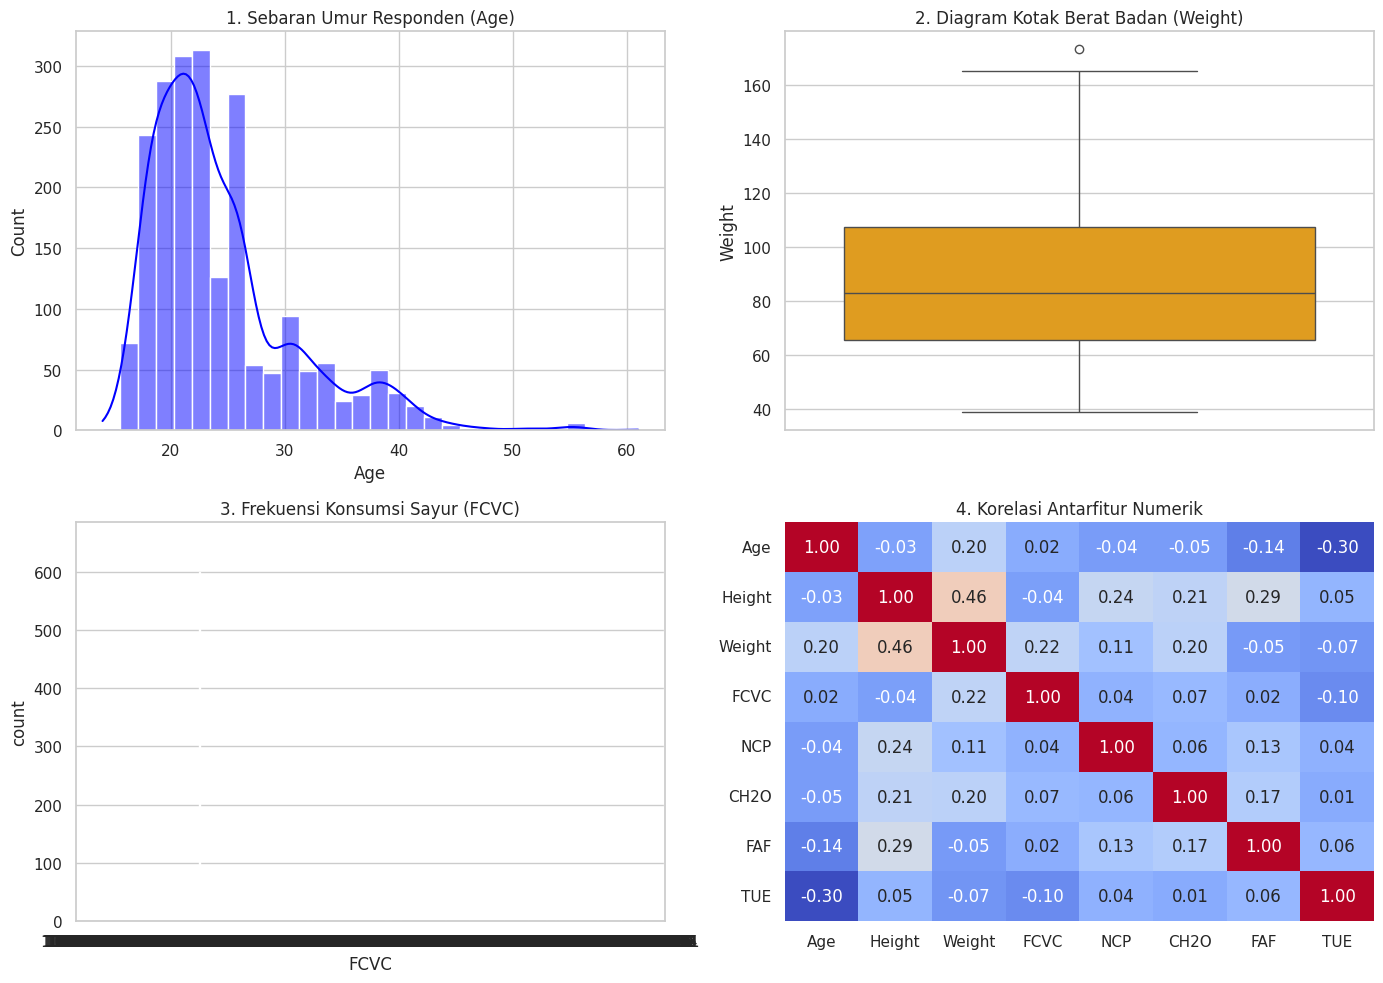

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Grafik 1: Sebaran Umur (Age)
sns.histplot(df['Age'], bins=30, kde=True, color='blue', ax=axes[0, 0])
axes[0, 0].set_title('1. Sebaran Umur Responden (Age)')

# Grafik 2: Sebaran Berat Badan (Weight)
sns.boxplot(y=df['Weight'], color='orange', ax=axes[0, 1])
axes[0, 1].set_title('2. Diagram Kotak Berat Badan (Weight)')

# Grafik 3: Frekuensi Konsumsi Sayur (FCVC)
sns.countplot(data=df, x='FCVC', hue='FCVC', palette='Set2', legend=False, ax=axes[1, 0])
axes[1, 0].set_title('3. Frekuensi Konsumsi Sayur (FCVC)')

# Grafik 4: Peta Panas Korelasi Fitur Numerik Utama
numeric_cols = df.select_dtypes(include=['number']).columns
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1, 1], cbar=False)
axes[1, 1].set_title('4. Korelasi Antarfitur Numerik')

plt.tight_layout()
plt.show()

### Penafsiran Visualisasi (Langkah 6)

1. **Grafik 1 (Sebaran Umur Responden / Age):** Sebaran usia responden terkonsentrasi pada rentang usia muda hingga dewasa awal (sebagian besar antara 14 hingga 30 tahun), dengan kurva *KDE* yang menunjukkan puncak kepadatan data di usia sekitar 20–22 tahun.
2. **Grafik 2 (Diagram Kotak Berat Badan / Weight):** Menunjukkan rentang variasi berat badan yang luas (dari 39 kg hingga 173 kg) dengan beberapa titik pencilan (*outliers*) di atas 160 kg yang mencerminkan kelompok responden dengan tingkat obesitas tertinggi.
3. **Grafik 3 (Frekuensi Konsumsi Sayur / FCVC):** Sebagian besar responden menunjukkan pola konsumsi sayur harian yang cukup sering, di mana kategori skor tertentu mendominasi frekuensi jawaban.
4. **Grafik 4 (Peta Panas Korelasi Antarfitur Numerik):** Terlihat hubungan korelasi antarfitur numerik utama, di mana beberapa fitur fisik menunjukkan keterkaitan yang menjadi landasan penting sebelum dilakukan standarisasi data untuk algoritma K-Means.

### Tabel Keputusan Praproses (Langkah 7)
| Kolom / Baris | Temuan | Keputusan | Alasan | Baris Terpengaruh |
| :--- | :--- | :--- | :--- | :--- |
| **Baris Duplikat** | Ditemukan 24 baris duplikat identik | Dihapus (`drop_duplicates()`) | Mencegah bias frekuensi ganda pada pembentukan klaster K-Means | 24 baris |
| **Kolom Kategori (Gender, FAVC, dll)** | Bertipe objek/teks (*string*) | Dicatat untuk *Encoding* (`LabelEncoder` / *One-Hot*) di tahap 02 | Algoritma K-Means memerlukan data berbentuk numerik/jarak | Seluruh kolom kategori |
| **Fitur Numerik (Age, Weight, FAF, dll)** | Rentang skala beragam (misal Berat 39-173 vs FAF 0-3) | Dicatat untuk *StandardScaler* setelah *split* / penyiapan data | K-Means sangat sensitif terhadap perbedaan skala nilai | Seluruh fitur numerik |

In [9]:
# Menyimpan dataset yang telah diverifikasi mutunya ke folder data
df_bersih = df.drop_duplicates().copy()
df_bersih.to_csv('data_bersih.csv', index=False)

print(f"Ukuran awal: {df.shape}")
print(f"Ukuran bersih: {df_bersih.shape}")
print("Berhasil menyimpan file 'data_bersih.csv'!")

Ukuran awal: (2111, 17)
Ukuran bersih: (2087, 17)
Berhasil menyimpan file 'data_bersih.csv'!
